# Понятие эталона. Отступы и классификация объектов качества

Сначала разберём необходимые понятия с нуля. Затем пройдём один цельный пример:
от измерений трафика и выбора эталонов до SVM и предварительного сигнала аналитику ИБ.

Для выполнения выберите **«Среда выполнения → Выполнить все» / Runtime → Run all**.
Все данные встроены. Google Drive, локальные файлы, GPU и ключи доступа не нужны.
Сохранённые таблицы и графики можно читать до запуска.


## Сначала — понятия

### Объект, признак и класс

**Объект** — то, что мы исследуем. **Признаки** — измеримые свойства объекта.
Все объекты описываются одинаковым набором признаков. **Класс** — одна из заранее
заданных групп. **Классификация** — выбор класса объекта по его признакам.

**Модель**, или классификатор, — правило такого выбора. **Обучающая выборка** —
примеры с заранее известными классами, то есть метками. **Обучение** — подбор правила
по этим примерам. Истинная метка и прогноз модели — разные вещи: прогноз может быть ошибочным.

### Эталон класса

**Эталон класса** — образец этого класса, принятый для сравнения с другими объектами.
Для каждого класса выбирается свой образец. Способ его выбора — отдельное решение.
Сначала определим, как измерять похожесть объектов.

### Расстояние и масштаб

Значения двух признаков можно представить как координаты точки.
**Евклидово расстояние** — расстояние по прямой между такими точками:
меньше расстояние — ближе описания объектов.
Признаки в разных единицах сначала приводят к выбранному масштабу. Иначе признак
с большими числами может подавить остальные. Масштаб влияет на результат сравнения.

### Выбор эталона: медоид

Мы используем **медоид** — существующий обучающий объект с наименьшей суммой
расстояний до остальных объектов своего класса. Для каждого кандидата складываем
расстояния, выбираем минимальную сумму и повторяем для каждого класса.
Проверочные объекты в выборе не участвуют.

**Правило ближайшего эталона:** посчитать расстояние до образца каждого класса
и выбрать класс ближайшего. При равных расстояниях нужна заранее заданная договорённость.

### Отступ как преимущество своего класса

**Отступ** выражает, насколько оценка истинного класса превосходит оценку конкурента.
Для эталона оценка класса равна минус расстоянию до его образца.
Поэтому для ближайшего эталона используем разность: **расстояние до чужого эталона минус
расстояние до своего**. Свой класс определяется истинной меткой, а не прогнозом.

- Положительный отступ: свой эталон ближе, ответ верен.
- Отрицательный: чужой эталон ближе, ответ ошибочен.
- Нулевой: расстояния равны.

Для проверки правильности по знаку нужна истинная метка. Без неё можно получить
прогноз и расстояния, но нельзя узнать, свой ли класс выбран.

### SVM, граница и мягкий зазор

Один эталон может грубо описывать разнообразие класса. **SVM** — метод опорных векторов. **Линейная SVM** обучает другое
правило по всей обучающей выборке. Для двух признаков её граница — прямая.
**Граница решения** — положения, при переходе через которые меняется прогноз.
Функция решения `f` имеет разные знаки по разные стороны границы; на самой границе `f=0`.
Эталоны остаются отдельным способом сравнения: две точки-медоида не заменяют выборку для SVM.

**Зазор** — полоса вокруг границы, которую SVM стремится сделать широкой.
**Мягкий зазор** допускает обучающие объекты внутри полосы и на ошибочной стороне,
назначая штраф за нарушения. `C` определяет цену этих нарушений.
**Опорные векторы** — обучающие объекты, участвующие в определении границы.

### Геометрический отступ и «запас прочности»

**Размеченный геометрический отступ SVM** — расстояние до границы со знаком:
плюс на правильной стороне и минус на ошибочной. Он тоже требует истинной метки.

**Расстояние без знака** показывает запас сохранения текущего ответа линейной модели:
минимальную длину произвольного изменения масштабированных признаков до границы.
Это не вероятность атаки и не гарантия правильности. Большой запас может сохранять
ошибочный ответ; допустимость реального изменения трафика это расстояние не проверяет.

Эталонный отступ `M_ref` и геометрический отступ SVM `γ` имеют разные определения.
**Их величины нельзя напрямую сравнивать:** разность двух расстояний не равна
расстоянию до границы SVM.

### Пограничные случаи и перепроверка

**Пограничный объект** близок к готовой границе: небольшое изменение признаков может
сменить прогноз. Пограничными бывают оба класса, верные ответы и ошибки.

Различайте две полосы:

- **Зазор SVM** участвует в обучении; его края задаются значениями функции `f = −1` и `f = +1`.
- **Полоса перепроверки** выбирается после обучения для обработки результатов.
  Её порог задаёт аналитик; он не следует из `C` и не обязан совпадать с зазором.

Теперь все понятия введены. Применим их последовательно к одной задаче.


## Единый пример: нормальный трафик и SYN-flood

Обычное TCP-рукопожатие: **SYN → SYN-ACK → ACK**.
При SYN-flood множество начатых подключений не завершается; занятая очередь
может мешать легитимным клиентам. Но потери сети и всплеск обычной нагрузки
тоже могут ухудшать наблюдаемые признаки.

**Все числа далее синтетические, придуманные вручную.** Есть 20 обучающих окон
и 8 специально выбранных проверок. Это иллюстрация поведения методов,
**не независимый бенчмарк качества**. Процент точности не используется как доказательство защиты.

### Шаг 1. Получим исходные признаки

Объект — неперекрывающееся **окно 10 секунд к одному IP и TCP-порту**.

- `SYN/с` — средняя частота всех входящих SYN-пакетов за окно, включая повторы.
- `Без рукопожатия, %` — доля начатых в окне попыток без полного рукопожатия
  за фиксированные 3 секунды. Повторы одной попытки объединяются.

Нужны оба направления трафика и ожидание тайм-аута последней попытки.
Окна без SYN-попыток исключаем: доля для них не определена. Учебная модель
принимает только положительный `SYN/с`.

Метки заданы автором: `−1` — норма, `+1` — SYN-flood. Сначала загрузим инструменты.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.svm import SVC
from IPython.display import display

label_ru = {-1: "Норма", 1: "SYN-flood"}
pd.set_option("display.max_columns", 12)
print("Данные встроены; внешние файлы не нужны.")


Данные встроены; внешние файлы не нужны.


Обучающие 20 окон: по 10 каждого класса. Только они будут задавать эталоны и SVM.


In [2]:
train_raw = pd.DataFrame([
    ['N01', 200, 5.0, -1], ['N02', 320, 8.0, -1],
    ['N03', 450, 10.0, -1], ['N04', 550, 8.0, -1],
    ['N05', 600, 15.0, -1], ['N06', 720, 12.0, -1],
    ['N07', 850, 18.0, -1], ['N08', 1050, 15.0, -1],
    ['N09', 920, 30.0, -1], ['N10', 750, 40.0, -1],
    ['A01', 1050, 65.0, 1], ['A02', 1200, 75.0, 1],
    ['A03', 1400, 82.0, 1], ['A04', 1600, 90.0, 1],
    ['A05', 1800, 92.0, 1], ['A06', 1300, 65.0, 1],
    ['A07', 1500, 75.0, 1], ['A08', 950, 60.0, 1],
    ['A09', 1100, 50.0, 1], ['A10', 800, 56.0, 1],
], columns=["ID", "SYN/с", "Без рукопожатия, %", "y"])
display(train_raw.assign(Класс=train_raw["y"].map(label_ru)).drop(columns="y"))


,ID,SYN/с,"Без рукопожатия, %",Класс
0,N01,200,5.0,Норма
1,N02,320,8.0,Норма
2,N03,450,10.0,Норма
3,N04,550,8.0,Норма
4,N05,600,15.0,Норма
5,N06,720,12.0,Норма
6,N07,850,18.0,Норма
7,N08,1050,15.0,Норма
8,N09,920,30.0,Норма
9,N10,750,40.0,Норма


Восемь проверочных окон не участвуют в выборе эталонов и обучении.
Они подобраны для объяснения, включая ошибки и близость к границе.
Окно **T07** проведём через оба правила, не меняя его признаки и метку.


In [3]:
check_raw = pd.DataFrame([
    ['T01', 420, 9.0, -1], ['T02', 1550, 88.0, 1],
    ['T03', 950, 40.0, -1], ['T04', 900, 40.0, 1],
    ['T05', 1000, 42.0, -1], ['T06', 950, 46.0, 1],
    ['T07', 1200, 16.0, -1], ['T08', 950, 75.0, 1],
], columns=["ID", "SYN/с", "Без рукопожатия, %", "y"])
display(check_raw.assign(Класс=check_raw["y"].map(label_ru)).drop(columns="y"))


,ID,SYN/с,"Без рукопожатия, %",Класс
0,T01,420,9.0,Норма
1,T02,1550,88.0,SYN-flood
2,T03,950,40.0,Норма
3,T04,900,40.0,SYN-flood
4,T05,1000,42.0,Норма
5,T06,950,46.0,SYN-flood
6,T07,1200,16.0,Норма
7,T08,950,75.0,SYN-flood


### Шаг 2. Зададим масштаб для измерения похожести

Делим частоту на 1000, а проценты на 100. Это заранее фиксированный учебный масштаб,
а не параметры, подобранные по проверочным меткам. T07 превращается из
`1200 SYN/с, 16%` в `(1.20; 0.16)`. Во всех следующих расчётах используем тот же масштаб.


In [4]:
feature_names = ["SYN/с", "Без рукопожатия, %"]
feature_scale = np.array([1000.0, 100.0])
X_train = train_raw[feature_names].to_numpy(dtype=float) / feature_scale
X_check = check_raw[feature_names].to_numpy(dtype=float) / feature_scale
y_train = train_raw["y"].to_numpy()
y_check = check_raw["y"].to_numpy()
t07_index = int(np.flatnonzero(check_raw["ID"].to_numpy() == "T07")[0])
print("T07 после масштабирования:", X_check[t07_index])


T07 после масштабирования: [1.2  0.16]


### Шаг 3. Выберем медоиды — по одному эталону на класс

Для каждого кандидата складываем расстояния до остальных обучающих точек своего
класса и выбираем наименьшую сумму. При равенстве сумм выбираем меньший ID.
Функция реализует именно описанное ранее правило медоида.


In [5]:
def choose_medoid(points, ids):
    distances = np.linalg.norm(points[:, None, :] - points[None, :, :], axis=2)
    sums = distances.sum(axis=1)
    tied = np.flatnonzero(np.isclose(sums, sums.min(), rtol=0, atol=1e-12))
    best = min(tied, key=lambda index: ids[index])
    return ids[best], points[best].copy(), float(sums[best]), sums

prototypes, candidate_rows, selected_rows = {}, [], []
for label in [-1, 1]:
    mask = y_train == label
    ids = train_raw.loc[mask, "ID"].to_numpy()
    ident, point, total, sums = choose_medoid(X_train[mask], ids)
    prototypes[label] = point
    selected_rows.append([label_ru[label], ident, *point, total])
    candidate_rows.extend([[label_ru[label], i, s] for i, s in zip(ids, sums)])
display(pd.DataFrame(selected_rows, columns=["Класс", "Медоид", "x1", "x2", "Минимальная сумма"]).round(6))


,Класс,Медоид,x1,x2,Минимальная сумма
0,Норма,N05,0.6,0.15,2.415511
1,SYN-flood,A06,1.3,0.65,2.882603


Эталоны: **N05 — 600 SYN/с и 15%**, **A06 — 1300 SYN/с и 65%**.
Это образцы данной выборки, а не универсальные пороги атаки.
Суммы расстояний всех кандидатов сохранены в `candidate_rows` и доступны в дополнении.

### Шаг 4. Проведём T07 через правило ближайшего эталона

Вход: **1200 SYN/с и 16%; истинный класс — норма**.
Для этого объекта «свой» эталон — норма, «чужой» — атака.


In [6]:
d_normal = np.linalg.norm(X_check - prototypes[-1], axis=1)
d_attack = np.linalg.norm(X_check - prototypes[1], axis=1)
score_difference = d_normal - d_attack
score_difference[np.isclose(score_difference, 0, rtol=0, atol=1e-12)] = 0
prototype_prediction = np.where(score_difference > 0, 1, -1)
margin_ref = y_check * score_difference
print(f"T07: до нормы {d_normal[t07_index]:.6f}; до атаки {d_attack[t07_index]:.6f}")
print("Прогноз по эталону:", label_ru[prototype_prediction[t07_index]])
print(f"Отступ чужой−свой: {d_attack[t07_index]:.6f} − {d_normal[t07_index]:.6f} = {margin_ref[t07_index]:.6f}")


T07: до нормы 0.600083; до атаки 0.500100
Прогноз по эталону: SYN-flood
Отступ чужой−свой: 0.500100 − 0.600083 = -0.099983


Атака оказалась ближе: **эталонное правило ошиблось**, отступ отрицателен.
Высокая легитимная нагрузка показывает ограничение одного образца.
Технически при равных расстояниях код выбирает норму; T03 равноудалён от образцов.
Такое равенство следует считать отдельным поводом для разбора.

### Шаг 5. Обучим альтернативное правило — SVM на всех 20 окнах

Используем ту же выборку и масштаб. Два медоида не заменяют обучающие данные.
`C=1` фиксирован для примера, без выбора по проверочным окнам.


In [7]:
model = SVC(kernel="linear", C=1.0, tol=1e-10, shrinking=False)
model.fit(X_train, y_train)
w = model.coef_[0]
b = float(model.intercept_[0])
norm_w = float(np.linalg.norm(w))
print(f"Коэффициенты: w={w.round(6)}, b={b:.6f}")
print("Обучающих окон:", len(X_train), "; опорных векторов:", len(model.support_))


Коэффициенты: w=[1.216667 2.116667], b=-2.047500
Обучающих окон: 20 ; опорных векторов: 12


### Шаг 6. Проверим то же самое T07 с помощью SVM

Ни измерения, ни истинную метку T07 не меняем. Для SVM получаем прогноз,
функцию `f`, размеченный геометрический отступ `γ` и неотрицательное расстояние `r`.
Все подробные определения доступны в математическом дополнении в конце.


In [8]:
prediction = model.predict(X_check)
f = model.decision_function(X_check)
m = y_check * f
gamma = m / norm_w
r = np.abs(f) / norm_w
print("T07, прогноз SVM:", label_ru[prediction[t07_index]])
print(f"f={f[t07_index]:+.6f}; γ={gamma[t07_index]:+.6f}; r={r[t07_index]:.6f}")


T07, прогноз SVM: Норма
f=-0.248833; γ=+0.101921; r=0.101921


Теперь прогноз — **норма, верно для известной метки**.
Положительный `γ ≈ 0.101921` фиксирует правильную сторону границы;
`r ≈ 0.101921` характеризует запас текущего ответа в выбранном масштабе.

Эталонный отступ `−0.099983` и SVM-отступ `+0.101921` **не сравниваем по величине**:
у них разные определения. В этой иллюстрации изменился результат классификации.
**Один исправленный пример не доказывает, что SVM всегда лучше.**

Посмотрим отдельно, что использовалось при обучении SVM: здесь только 20 обучающих
точек, опорные векторы и полоса между `f=−1` и `f=+1`. Проверочных окон на этом графике нет.


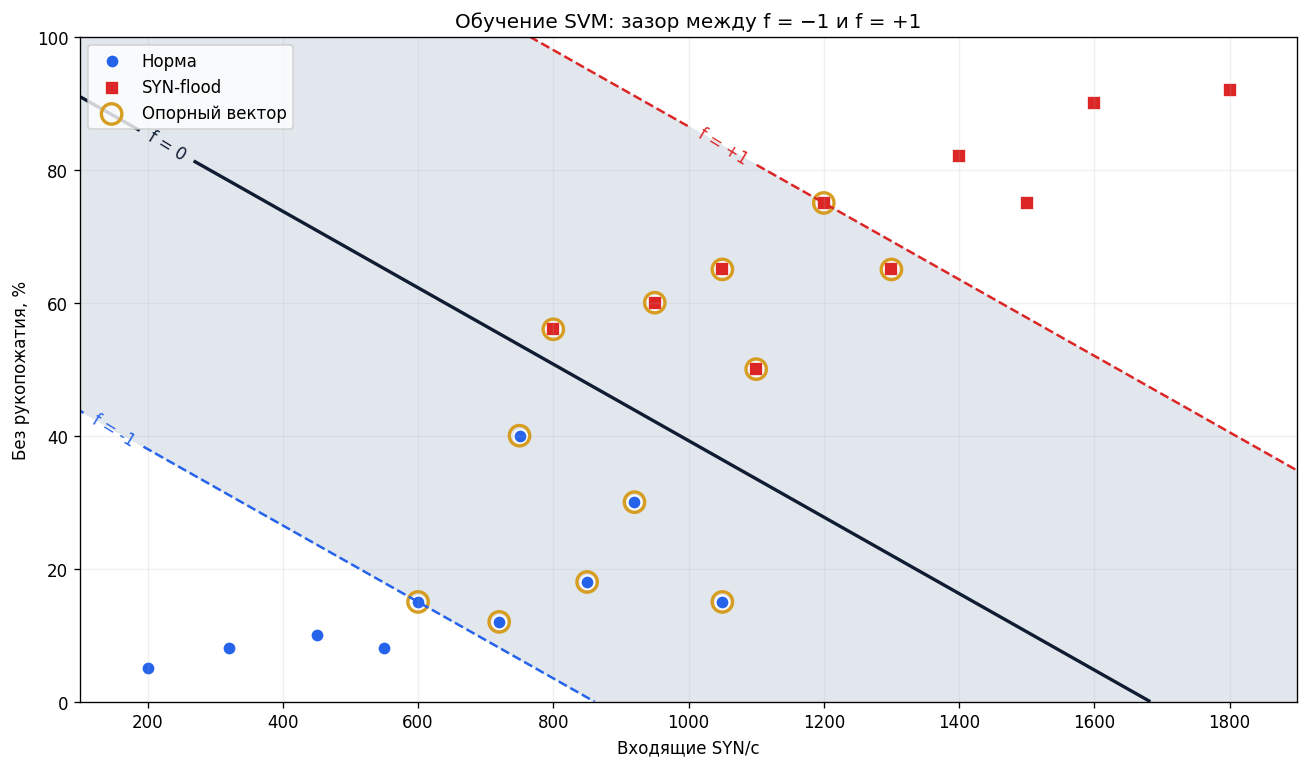

In [9]:
grid_syn, grid_percent = np.meshgrid(np.linspace(100, 1900, 400), np.linspace(0, 100, 300))
grid_features = np.column_stack([grid_syn.ravel(), grid_percent.ravel()]) / feature_scale
grid_f = model.decision_function(grid_features).reshape(grid_syn.shape)
blue, red, ink, grey, gold = "#2563EB", "#DC2626", "#101C32", "#CBD5E1", "#D69D20"
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.contourf(grid_syn, grid_percent, grid_f, levels=[-1, 1], colors=[grey], alpha=0.55)
lines = ax.contour(grid_syn, grid_percent, grid_f, levels=[-1, 0, 1], colors=[blue, ink, red],
                   linestyles=["--", "-", "--"], linewidths=[1.5, 2, 1.5])
ax.clabel(lines, fmt={-1: "f = -1", 0: "f = 0", 1: "f = +1"}, fontsize=10)
for label, marker, color in [(-1, "o", blue), (1, "s", red)]:
    mask = y_train == label
    ax.scatter(train_raw.loc[mask, "SYN/с"], train_raw.loc[mask, "Без рукопожатия, %"],
               marker=marker, c=color, s=65, edgecolor="white", label=label_ru[label])
support_raw = train_raw.iloc[model.support_]
ax.scatter(support_raw["SYN/с"], support_raw["Без рукопожатия, %"], s=150,
           facecolor="none", edgecolor=gold, linewidth=2, label="Опорный вектор")
ax.set(xlim=(100, 1900), ylim=(0, 100), xlabel="Входящие SYN/с", ylabel="Без рукопожатия, %",
       title="Обучение SVM: зазор между f = −1 и f = +1")
ax.grid(alpha=0.18)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()


### Шаг 7. Повторим расчёт для всех восьми окон

Истинные метки известны автору учебных данных. Сравним их с прогнозом и вычислим
отступы. Это оценочный разбор иллюстраций; новые объекты без метки не позволяют
сразу определить знак правильности `γ` или `M_ref`.


In [10]:
all_checks = pd.DataFrame({"ID": check_raw["ID"],
    "Истинный класс": [label_ru[y] for y in y_check],
    "Прогноз SVM": [label_ru[y] for y in prediction],
    "f": f, "m = y*f": m, "γ": gamma, "r": r, "M_ref": margin_ref})
display(all_checks.round(6))


,ID,Истинный класс,Прогноз SVM,f,m = y*f,γ,r,M_ref
0,T01,Норма,Норма,-1.346000,1.346000,0.551317,0.551317,0.853336
1,T02,SYN-flood,SYN-flood,1.701000,1.701000,0.696724,0.696724,0.858376
2,T03,Норма,Норма,-0.045000,0.045000,0.018432,0.018432,-0.000000
3,T04,SYN-flood,Норма,-0.105833,-0.105833,-0.043349,0.043349,-0.081187
4,T05,Норма,SYN-flood,0.058167,-0.058167,-0.023825,0.023825,-0.104576
5,T06,SYN-flood,SYN-flood,0.082000,0.082000,0.033587,0.033587,0.069301
6,T07,Норма,Норма,-0.248833,0.248833,0.101921,0.101921,-0.099983
7,T08,SYN-flood,SYN-flood,0.695833,0.695833,0.285011,0.285011,0.330617


### Шаг 8. Выделим малый запас и разберём ошибки

Для демонстрации зададим **r < 0.10** после обучения.
Это условная полоса перепроверки, а не найденный SVM зазор и не правило обнаружения атак.


In [11]:
TAU = 0.10
boundary_review = r < TAU
print("Пограничные окна:", ", ".join(check_raw.loc[boundary_review, "ID"]))
error_mask = prediction != y_check
error_table = all_checks.loc[error_mask, ["ID", "Истинный класс", "Прогноз SVM", "γ", "r"]].copy()
error_table["Тип ошибки"] = ["Пропуск атаки" if y == 1 else "Ложная тревога" for y in y_check[error_mask]]
display(error_table.round(6))


,ID,Истинный класс,Прогноз SVM,γ,r,Тип ошибки
3,T04,SYN-flood,Норма,-0.043349,0.043349,Пропуск атаки
4,T05,Норма,SYN-flood,-0.023825,0.023825,Ложная тревога


Пограничные окна: T03, T04, T05, T06


Получились **T03, T04, T05, T06**. T04 — атака, принятая за норму (**пропуск**);
T05 — нормальный трафик, принятый за атаку (**ложная тревога**).
T03 и T06 тоже пограничные, но классифицированы верно.

Обе показанные ошибки попали в перепроверку. Это не гарантия обнаружения любых ошибок.
T07 с `r ≈ 0.101921` едва вне выбранного порога; число 0.10 не создаёт гарантии.

Второй график содержит только восемь проверочных окон. **Серая полоса теперь
обозначает r < 0.10**, а не `f=±1`. Значок × отмечает известную ошибку.
Цвет точки — истинный класс, не прогноз.


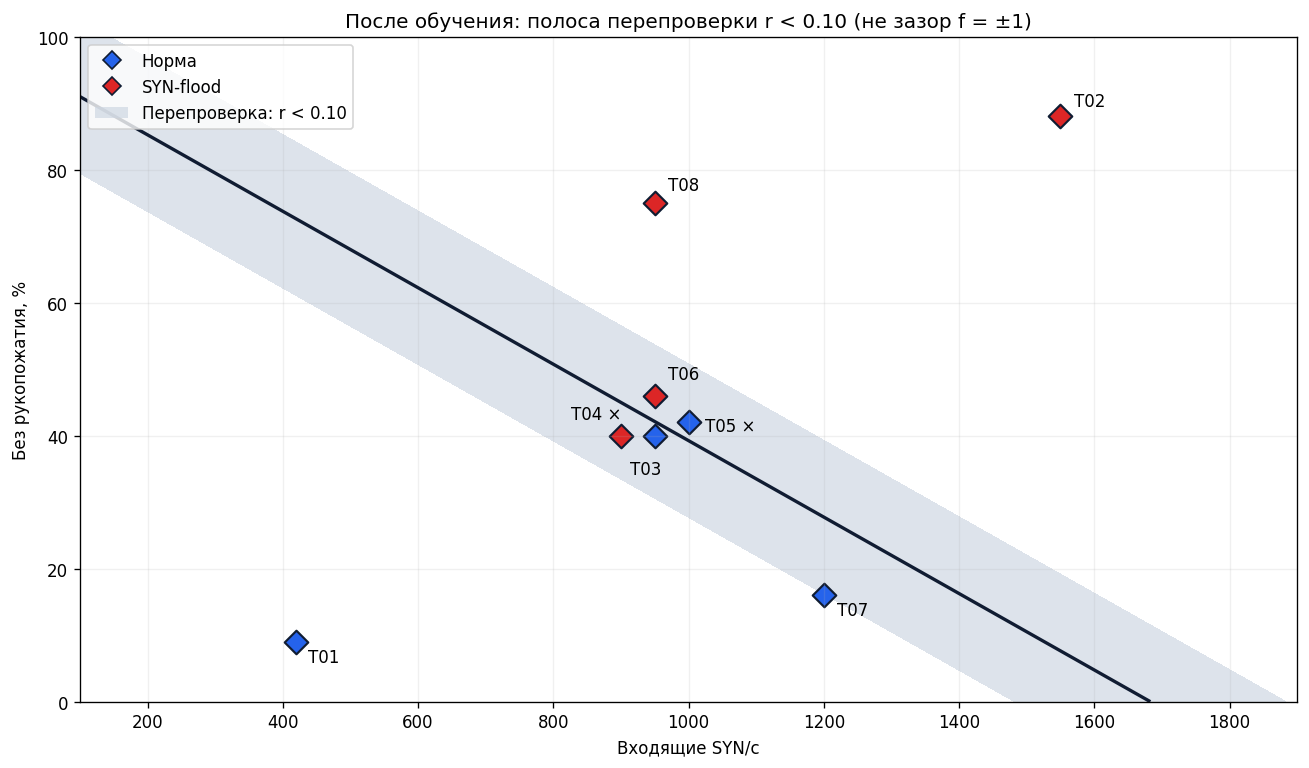

In [12]:
grid_r = np.abs(grid_f) / norm_w
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.contourf(grid_syn, grid_percent, grid_r, levels=[0, TAU], colors=[grey], alpha=0.65)
ax.contour(grid_syn, grid_percent, grid_f, levels=[0], colors=[ink], linewidths=2)
offsets = [(7, -12), (8, 6), (-15, -23), (-30, 10), (10, -5), (8, 10), (8, -12), (8, 8)]
for index, row in check_raw.iterrows():
    color = blue if row["y"] == -1 else red
    ax.scatter(row["SYN/с"], row["Без рукопожатия, %"], marker="D", c=color,
               s=100, edgecolor=ink, linewidth=1.3)
    text = row["ID"] + (" ×" if error_mask[index] else "")
    ax.annotate(text, (row["SYN/с"], row["Без рукопожатия, %"]),
                xytext=offsets[index], textcoords="offset points", fontsize=10)
handles = [Line2D([], [], marker="D", color="none", markerfacecolor=c, markeredgecolor=ink,
                  markersize=8, label=label_ru[y]) for y, c in [(-1, blue), (1, red)]]
handles.append(Patch(facecolor=grey, alpha=0.65, label="Перепроверка: r < 0.10"))
ax.set(xlim=(100, 1900), ylim=(0, 100), xlabel="Входящие SYN/с", ylabel="Без рукопожатия, %",
       title="После обучения: полоса перепроверки r < 0.10 (не зазор f = ±1)")
ax.grid(alpha=0.18)
ax.legend(handles=handles, loc="upper left")
fig.tight_layout()
plt.show()


### Шаг 9. Передадим результат аналитику ИБ

SOC — команда мониторинга и реагирования на события ИБ.
Для предварительной сортировки используем **два отдельных флага**:

- `attack_alert`: модель предсказала атаку при любом запасе.
- `boundary_review`: запас мал при любом прогнозе.

Очередь близких к границе объектов не является ранжированием общего риска инцидентов
и не заменяет очередь алертов. При прогнозе атаки большое расстояние не отменяет алерт.

Функция принимает SYN/с и проценты, применяет тот же масштаб и выдаёт рекомендацию.
Истинной метки у неё нет. **Она не блокирует трафик и не меняет настройки сети.**


In [13]:
def triage(syn_per_second, unfinished_percent):
    values = np.array([syn_per_second, unfinished_percent], dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("Нужны конечные числовые значения.")
    if values[0] <= 0:
        raise ValueError("Для классификации нужен положительный SYN/с; окна без попыток исключаем")
    if not 0 <= values[1] <= 100:
        raise ValueError("Доля незавершённых рукопожатий должна быть от 0 до 100%.")
    features = values.reshape(1, -1) / feature_scale
    predicted = int(model.predict(features)[0])
    distance = abs(float(model.decision_function(features)[0])) / norm_w
    alert, review = predicted == 1, bool(distance < TAU)
    action = ("Алерт + перепроверка" if review else "Алерт") if alert else ("Перепроверка" if review else "Наблюдение")
    return {"predicted_class": label_ru[predicted], "attack_alert": alert,
            "boundary_review": review, "r": round(distance, 6), "action": action}


Пять входов ниже — только измерения и ответы функции, без истинных меток.
Проверьте два контрастных случая: `(900, 40)` даёт норму с перепроверкой,
а `(1550, 88)` — алерт атаки без пограничной перепроверки.


In [14]:
demo_inputs = [(420, 9), (1550, 88), (950, 40), (900, 40), (1000, 42)]
demo_rows = [{"SYN/с": syn, "Без рукопожатия, %": percent, **triage(syn, percent)}
             for syn, percent in demo_inputs]
display(pd.DataFrame(demo_rows))


,SYN/с,"Без рукопожатия, %",predicted_class,attack_alert,boundary_review,r,action
0,420,9,Норма,False,False,0.551317,Наблюдение
1,1550,88,SYN-flood,True,False,0.696724,Алерт
2,950,40,Норма,False,True,0.018432,Перепроверка
3,900,40,Норма,False,True,0.043349,Перепроверка
4,1000,42,SYN-flood,True,True,0.023825,Алерт + перепроверка


Далее аналитик сопоставляет сигналы с логами, доступностью сервиса, очередью соединений,
потерями и контекстом нагрузки. Для рабочей системы нужны реальные данные, отдельная
валидация на более поздних периодах, оценка пропусков и ложных тревог, дополнительные
признаки и проверенная политика реагирования. Этот пример не доказывает готовность к внедрению.

Весь путь пройден: одни признаки → масштаб → эталоны → T07 → SVM на той же выборке →
тот же T07 → восемь проверок → пограничные случаи и отдельный алерт.


## Необязательное математическое дополнение

| Величина | Определение и смысл |
|---|---|
| `M_ref` | Расстояние до чужого эталона минус расстояние до своего; не расстояние до границы SVM |
| `f = w₁x₁ + w₂x₂ + b` | Функция решения SVM: минус — норма, плюс — атака |
| `m = y*f` | Функциональный размеченный отступ |
| `γ = y*f / ‖w‖` | Геометрический размеченный отступ SVM |
| `r = abs(f) / ‖w‖ = abs(γ)` | Неотрицательное расстояние до гиперплоскости в выбранном масштабе |
| `max(0, 1−m)` | Hinge loss: штраф за недостаточный отступ |
| `2 / ‖w‖` | Ширина номинальной полосы обучения между `f=−1` и `f=+1` |

Здесь `y=−1` для нормы и `y=+1` для SYN-flood. Для проверки правильности по знаку
`m`, `γ` и `M_ref` нужна известная метка. Расстояние `r` и прогноз доступны без неё.

На обучающих точках минимальная slack-переменная равна `max(0, 1−m)`.
На проверках это hinge loss для анализа, а не переменная уже решённой задачи обучения.
Только обучающие точки могут быть опорными векторами.


In [15]:
details = all_checks.copy()
details["hinge = max(0, 1-m)"] = np.maximum(0, 1-m)
display(details.round(6))
print(f"‖w‖ = {norm_w:.9f}; ширина обучения 2/‖w‖ = {2/norm_w:.9f}")
print("Опорные ID:", ", ".join(train_raw.iloc[model.support_]["ID"]))
display(pd.DataFrame(candidate_rows, columns=["Класс", "Кандидат", "Сумма расстояний"]).round(6))


,ID,Истинный класс,Прогноз SVM,f,m = y*f,γ,r,M_ref,"hinge = max(0, 1-m)"
0,T01,Норма,Норма,-1.346000,1.346000,0.551317,0.551317,0.853336,0.000000
1,T02,SYN-flood,SYN-flood,1.701000,1.701000,0.696724,0.696724,0.858376,0.000000
2,T03,Норма,Норма,-0.045000,0.045000,0.018432,0.018432,-0.000000,0.955000
3,T04,SYN-flood,Норма,-0.105833,-0.105833,-0.043349,0.043349,-0.081187,1.105833
4,T05,Норма,SYN-flood,0.058167,-0.058167,-0.023825,0.023825,-0.104576,1.058167
5,T06,SYN-flood,SYN-flood,0.082000,0.082000,0.033587,0.033587,0.069301,0.918000
6,T07,Норма,Норма,-0.248833,0.248833,0.101921,0.101921,-0.099983,0.751167
7,T08,SYN-flood,SYN-flood,0.695833,0.695833,0.285011,0.285011,0.330617,0.304167


,Класс,Кандидат,Сумма расстояний
0,Норма,N01,4.599751
1,Норма,N02,3.623601
2,Норма,N03,2.862364
3,Норма,N04,2.572858
4,Норма,N05,2.415511
5,Норма,N06,2.520975
6,Норма,N07,2.904168
7,Норма,N08,4.268772
8,Норма,N09,3.499612
9,Норма,N10,3.392102


‖w‖ = 2.441425022; ширина обучения 2/‖w‖ = 0.819193701
Опорные ID: N05, N06, N07, N08, N09, N10, A01, A02, A06, A08, A09, A10


### Формализация мягкого зазора

$$\min_{w,b,\xi}\; \frac{1}{2}\lVert w\rVert^2 + C\sum_i\xi_i.$$

$$y_i(w^\mathsf{T}x_i+b)\ge 1-\xi_i,\qquad \xi_i\ge 0.$$

`C` задаёт цену нарушения отступа: чем больше `C`, тем сильнее штраф.
Номинальная полоса обучения определяется `f=±1`, а полоса перепроверки — отдельно выбранным `r<0.10`.

### Источники

- [scikit-learn: SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)
- [scikit-learn: support vector machines](https://scikit-learn.org/stable/modules/svm.html)
- [RFC 4987: TCP SYN Flooding Attacks and Common Mitigations](https://www.rfc-editor.org/rfc/rfc4987)

Источники объясняют метод и контекст атаки. Числа ноутбука — авторская синтетическая
иллюстрация, а не данные из этих источников.
